# Cyprus Property Intelligence

## Project Overview

This project collects, cleans, processes, analyzes, and visualizes residential
property listing data from Cyprus.

The main objective is to transform publicly available property listings into
a structured dataset that can be used to investigate property prices,
price per square metre, property size, bedrooms, and geographical differences
across Cyprus.

### Project Pipeline

1. Web Scraping
2. Data Cleaning
3. Data Processing
4. Exploratory Data Analysis
5. Dashboard Dataset Preparation
6. Interactive Dashboard Development

## Technologies Used

- Python
- Requests
- BeautifulSoup
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook
- Looker Studio
- Git & GitHub
- Azure Virtual Machine

# 1. Web Scraping

The first stage of the project involved collecting property listing URLs
and extracting relevant information from individual property pages.

The scraped variables include property identification, location, asking
price, price per square metre, number of bedrooms and bathrooms, covered
area, parking availability, and floor information.

## 1.1 Import Libaries

In [3]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

## 1.2 Define the Source Website

The Property listings were collected from Index.cy. The scraping process first identifies property listing URLs and then visits individual listing pages to extract the required property attributes

In [4]:
url = "https://index.cy/sale/10687089-1-bedroom-apartment-for-sale-in-livadia-larnakas-larnaca-district/?_gl=1*ff0uhr*_up*MQ..*_gs*MQ..&gclid=CjwKCAjww-3VBhAcEiwAwUUIuz4JYGsf8d7JfDF-D52gCK2IxXCiPD9fjXSmUnJXIeWKpn76l7EUOBoCvqcQAvD_BwE&gbraid=0AAAAAqOs-DjzQMLqTi6i4A0wVKYFksw1G#overview"
headers = {"User-Agent":"mozill/5.0"}
response = requests.get(url,headers = headers)
if response.status_code ==200:
    print("successful")
else:
    print("failed:",response.status_code)

successful


In [5]:
soup = BeautifulSoup(response.content,"html.parser")
print(soup.title.text)

1 Bedroom Apartment for Sale in Livadia Larnakas, Larnaca District €209000 - INDEX.cy


In [6]:
#for this project i will inspect links and property containers
links = soup.find_all("a")
print("number of links:",len(links))

number of links: 201


In [7]:
for i, link in enumerate(links[:20]):
    print(i,link.get_text(" ",strip =True)[:150])
    

0 
1 Buy Αγορά Купить קנייה
2 Rent Ενοικίαση Аренда השכרה
3 Auctions Πλειστηριασμοί Аукционы מכירות פומביות
4 Map Χάρτης Карта מפה
5 Insights Αναλύσεις Аналитика תובנות
6 Companies Εταιρείες Компании חברות
7 Info Info Инфо מידע
8 EN
9 EL
10 RU
11 HE
12 
13 
14 Sign in Σύνδεση Войти התחברות
15 List a property Καταχώριση ακινήτου Разместить объявление פרסום נכס
16 Buy Αγορά Купить קנייה
17 Rent Ενοικίαση Аренда השכרה
18 Auctions Πλειστηριασμοί Аукционы מכירות פומביות
19 Map Χάρτης Карта מפה


In [8]:
#identify property card elements
properties = soup.select(".PROPERTY_CARD_SELECT OR")
print("number of properties:",len(properties))

number of properties: 0


In [9]:
cards = soup.find_all("div",class_="property-card")

In [10]:
title = soup.select_one(".lv2-title").get_text(" ",strip = True)

In [11]:
print("title")

title


In [12]:
print(title)

1 Bedroom Apartment for Sale in Livadia Larnakas, Larnaca District


In [13]:
location = soup.select_one(".lv2-meta-place").get_text(" ",strip = True)
print(location)

Livadia Larnakas, Larnaca district


In [14]:
property_id = soup.select_one(".lv2-meta-id").get_text(" ",strip = True)
print(property_id)

ID 10687089


In [15]:
price = soup.select_one(".lv2-price").get_text(" ",strip = True)
price_per_m_sq = soup.select_one(".lv2-ppm").get_text(" ",strip = True)
print(price)
print(price_per_m_sq)

€209,000
€2,787/m²


In [16]:
bedrooms = soup.select_one('.lv2-fact[title^="Bedrooms"] strong').get_text(" ", strip = True)

In [17]:
print(bedrooms)

1


In [18]:
bathrooms = soup.select_one('.lv2-fact[title^="Bathrooms"] strong').get_text(" ", strip = True)
covered_area = soup.select_one('.lv2-fact[title^="Covered area"] strong').get_text(" ", strip = True)
parking = soup.select_one('.lv2-fact[title^="Parking"] strong').get_text(" ", strip = True)
floor = soup.select_one('.lv2-fact[title^="Floor"] strong').get_text(" ", strip = True)
print(bathrooms)
print(covered_area)
print(parking)
print(floor)

1
75 m²
Yes
2


In [19]:
property_data = {
    "property_id": property_id,
    "title": title,
    "location": location,
    "price":price,
    "price_per_m2": price_per_m_sq,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms,
    "covered_area": covered_area,
    "parking": parking,
    "floor": floor
}
df = pd.DataFrame([property_data])
df


,property_id,title,location,price,price_per_m2,bedrooms,bathrooms,covered_area,parking,floor
0,ID 10687089,1 Bedroom Apartment for Sale in Livadia Larnak...,"Livadia Larnakas, Larnaca district","€209,000","€2,787/m²",1,1,75 m²,Yes,2


In [20]:
#getting the rest of the data
property_links = soup.select("article.sv2-card a.sv2-track[hresf]")
print("Number of property links:",len(property_links))

Number of property links: 0


In [21]:
url = "https://index.cy/for-sale/"
headers = {"User-Agent":"mozilla/5.o"}
response = requests.get(url,headers = headers)
if response.status_code ==200:
    print("successful")
else:
    print("failed:",response.status_code)

successful


In [22]:
soup = BeautifulSoup(response.content,'html.parser')
print(soup.title.text)


Property for Sale - Apartments & Houses - Cyprus Real Estate


In [23]:
property_links = soup.select("article.sv2-card a.sv2-track[hresf]")
print("Number of property links:",len(property_links))

Number of property links: 0


In [24]:
print(len(soup.find_all("article")))

24


In [25]:
print("sv2-card" in response.text)

True


In [26]:
articles = soup.find_all("article")
print(articles[0].get("class"))

['lv2-lcard', 'sv2-card', 'is-premium']


In [27]:
#inspect the links
links = articles[0].find_all("a")
for link in links:
    print(link.get("class"),link.get("href"))

['sv2-track'] https://index.cy/sale/11739916-4-bedroom-house-for-sale-in-larnaca-district/
['lv2-lcard-title'] https://index.cy/sale/11739916-4-bedroom-house-for-sale-in-larnaca-district/


## 1.3 Collect Property Listing URLs
The first scraping step was to indentify individual property listing URLs from the website. These URLs were then used as inputs for extracting property-level information

In [28]:
#find all sv2-track links
property_links = soup.find_all("a",class_="sv2-track")
print("Number of property links:",len(property_links) )

Number of property links: 24


In [29]:
#inspect the first 5
for link in property_links[:5]:
    print(link.get("href"))

https://index.cy/sale/11739916-4-bedroom-house-for-sale-in-larnaca-district/
https://index.cy/sale/10659805-3-bedroom-house-for-sale-in-tremithousa-paphos-district/
https://index.cy/sale/11688774-2-bedroom-apartment-for-sale-in-oroklini-larnaca-district/
https://index.cy/sale/11545923-2-bedroom-apartment-for-sale-in-palodeia-limassol-district/
https://index.cy/sale/10866479-3-bedroom-apartment-for-sale-in-livadia-larnakas-larnaca-district/


In [30]:
# turn the list into a python list
property_urls = [link.get("href") for link in property_links]
print("Number of urls:",len(property_urls))

Number of urls: 24


In [31]:
print(property_urls[:5])

['https://index.cy/sale/11739916-4-bedroom-house-for-sale-in-larnaca-district/', 'https://index.cy/sale/10659805-3-bedroom-house-for-sale-in-tremithousa-paphos-district/', 'https://index.cy/sale/11688774-2-bedroom-apartment-for-sale-in-oroklini-larnaca-district/', 'https://index.cy/sale/11545923-2-bedroom-apartment-for-sale-in-palodeia-limassol-district/', 'https://index.cy/sale/10866479-3-bedroom-apartment-for-sale-in-livadia-larnakas-larnaca-district/']


In [32]:
#some properties dont have floor numbers so this avoids errors
def get_text_or_none(soup, selector):
    element = soup.select_one(selector)

    if element:
        return element.get_text(" ", strip=True)

    return None

In [33]:
#create a scraper
def scrape_property(url):

    response = requests.get(url, headers=headers)

    soup = BeautifulSoup(response.content, "html.parser")

    title = get_text_or_none(soup, ".lv2-title")

    location = get_text_or_none(soup, ".lv2-meta-place")

    property_id = get_text_or_none(soup, ".lv2-meta-id")

    price = get_text_or_none(soup, ".lv2-price")

    price_per_m2 = get_text_or_none(soup, ".lv2-ppm")

    bedrooms = get_text_or_none(
        soup,
        '.lv2-fact[title^="Bedrooms"] strong'
    )

    bathrooms = get_text_or_none(
        soup,
        '.lv2-fact[title^="Bathrooms"] strong'
    )

    covered_area = get_text_or_none(
        soup,
        '.lv2-fact[title^="Covered area"] strong'
    )

    parking = get_text_or_none(
        soup,
        '.lv2-fact[title^="Parking"] strong'
    )

    floor = get_text_or_none(
        soup,
        '.lv2-fact[title^="Floor"] strong'
    )

    return {
        "property_id": property_id,
        "title": title,
        "location": location,
        "price": price,
        "price_per_m2": price_per_m2,
        "bedrooms": bedrooms,
        "bathrooms": bathrooms,
        "covered_area": covered_area,
        "parking": parking,
        "floor": floor
    }


In [34]:
#now lets run the scraper across all 24 urls
properties = []

for i, url in enumerate(property_urls, start=1):
    property_data = scrape_property(url)
    properties.append(property_data)

    print(f"Scraped {i}/{len(property_urls)}")

Scraped 1/24


Scraped 2/24
Scraped 3/24
Scraped 4/24
Scraped 5/24
Scraped 6/24
Scraped 7/24
Scraped 8/24
Scraped 9/24
Scraped 10/24
Scraped 11/24
Scraped 12/24
Scraped 13/24
Scraped 14/24
Scraped 15/24
Scraped 16/24
Scraped 17/24
Scraped 18/24
Scraped 19/24
Scraped 20/24
Scraped 21/24
Scraped 22/24
Scraped 23/24
Scraped 24/24


## 1.4 Extraction Property Attributes 

Each property listing URL was visited individually and relevant property attributes were extracted from the listing page. The extracted attributes include:
- Property attributes
- Property title
- District 
- Location 
- Asking Price 
- Price Per square metre
- Number of Bedrooms 
- Number of Bathrooms
- covered area 
- Parking availability 
- Floor information

## 1.5 Create the raw Property Dataset

In [35]:
df_properties = pd.DataFrame(properties)
df_properties


,property_id,title,location,price,price_per_m2,bedrooms,bathrooms,covered_area,parking,floor
0,ID 11739916,4 Bedroom House for Sale in Larnaca District,Larnaca district,"€1,100,000","€2,857/m²",4,4,385 m²,None,None
1,ID 10659805,"3 Bedroom House for Sale in Tremithousa, Papho...","Tremithousa, Paphos district","€320,000","€2,909/m²",3,2,110 m²,None,None
2,ID 11688774,"2 Bedroom Apartment for Sale in Oroklini, Larn...","Oroklini, Larnaca district","€275,000","€3,819/m²",2,3,72 m²,Covered,None
3,ID 11545923,"2 Bedroom Apartment for Sale in Palodeia, Lima...","Palodeia, Limassol district","€170,000","€2,179/m²",2,1,78 m²,Covered,None
4,ID 10866479,3 Bedroom Apartment for Sale in Livadia Larnak...,"Livadia Larnakas, Larnaca district","€270,000","€2,143/m²",3,2,126 m²,Covered,1 of 3
5,ID 10881780,3 Bedroom Apartment for Sale in Potamos Germas...,"Potamos Germasogeias, Limassol district","€750,000","€5,859/m²",3,2,128 m²,Covered,None
6,ID 11281010,1 Bedroom Apartment for Sale in Kato Paphos,"Kato Paphos, Paphos district","€285,000","€4,831/m²",1,1,59 m²,Covered,1 of 3
7,ID 10661588,1 Bedroom Apartment for Sale in Limassol – Nea...,"Limassol - Neapolis, Limassol district","€300,000","€4,478/m²",1,1,67 m²,Covered,None
8,ID 10560891,2 Bedroom Apartment for Sale in Larnaca – Fini...,"Larnaca - Finikoudes, Larnaca district","€325,000","€3,186/m²",2,2,102 m²,Covered,1 of 5
9,ID 10725022,3 Bedroom Apartment for Sale in Larnaca – Chry...,"Larnaca - Chrysopolitissa, Larnaca district","€508,000","€4,269/m²",3,1,119 m²,Covered,None


## 1.6 Scraping Summary 
The scraping stage successfully collected 24 residential property listings. The extracted information was constructed into a pandas dataframe containing property identification, location, pricing , property size,bedrooms, bathrooms,parking, and floor related information.
The resulting dataset is used as the starting point for the data cleaning processing stages.

# 2. Data Cleaning

The raw property dataset was cleaned and standardized before exploratory
data analysis. The cleaning process focused on removing unnecessary
characters, standardizing categorical values, converting numerical
variables to appropriate data types, handling missing values, and
standardizing property floor information.

The following cleaning operations were performed:

- Cleaned property identifiers
- Standardized text fields
- Converted price and property measurements to numeric formats
- Standardized categorical variables
- Investigated and handled missing values
- Cleaned floor information
- Checked the resulting dataset for consistency and data quality

In [41]:
df_properties['property_id'] = df_properties['property_id'].str.replace("ID ","",regex = False)
df_properties.head()

,property_id,title,location,price,price_per_m2,bedrooms,bathrooms,covered_area,parking,floor
0,11739916,4 Bedroom House for Sale in Larnaca District,Larnaca district,"€1,100,000","€2,857/m²",4,4,385 m²,None,None
1,10659805,"3 Bedroom House for Sale in Tremithousa, Papho...","Tremithousa, Paphos district","€320,000","€2,909/m²",3,2,110 m²,None,None
2,11688774,"2 Bedroom Apartment for Sale in Oroklini, Larn...","Oroklini, Larnaca district","€275,000","€3,819/m²",2,3,72 m²,Covered,None
3,11545923,"2 Bedroom Apartment for Sale in Palodeia, Lima...","Palodeia, Limassol district","€170,000","€2,179/m²",2,1,78 m²,Covered,None
4,10866479,3 Bedroom Apartment for Sale in Livadia Larnak...,"Livadia Larnakas, Larnaca district","€270,000","€2,143/m²",3,2,126 m²,Covered,1 of 3


In [42]:
df_properties['property_id'] = pd.to_numeric(df_properties['property_id'])
df_properties['property_id'].dtypes

dtype('int64')

In [43]:
df_properties['title'] = df_properties['title'].str.strip()
df_properties.head()

,property_id,title,location,price,price_per_m2,bedrooms,bathrooms,covered_area,parking,floor
0,11739916,4 Bedroom House for Sale in Larnaca District,Larnaca district,"€1,100,000","€2,857/m²",4,4,385 m²,None,None
1,10659805,"3 Bedroom House for Sale in Tremithousa, Papho...","Tremithousa, Paphos district","€320,000","€2,909/m²",3,2,110 m²,None,None
2,11688774,"2 Bedroom Apartment for Sale in Oroklini, Larn...","Oroklini, Larnaca district","€275,000","€3,819/m²",2,3,72 m²,Covered,None
3,11545923,"2 Bedroom Apartment for Sale in Palodeia, Lima...","Palodeia, Limassol district","€170,000","€2,179/m²",2,1,78 m²,Covered,None
4,10866479,3 Bedroom Apartment for Sale in Livadia Larnak...,"Livadia Larnakas, Larnaca district","€270,000","€2,143/m²",3,2,126 m²,Covered,1 of 3


In [44]:
df_properties['location'] = df_properties['location'].str.strip()
df_properties.head()

,property_id,title,location,price,price_per_m2,bedrooms,bathrooms,covered_area,parking,floor
0,11739916,4 Bedroom House for Sale in Larnaca District,Larnaca district,"€1,100,000","€2,857/m²",4,4,385 m²,None,None
1,10659805,"3 Bedroom House for Sale in Tremithousa, Papho...","Tremithousa, Paphos district","€320,000","€2,909/m²",3,2,110 m²,None,None
2,11688774,"2 Bedroom Apartment for Sale in Oroklini, Larn...","Oroklini, Larnaca district","€275,000","€3,819/m²",2,3,72 m²,Covered,None
3,11545923,"2 Bedroom Apartment for Sale in Palodeia, Lima...","Palodeia, Limassol district","€170,000","€2,179/m²",2,1,78 m²,Covered,None
4,10866479,3 Bedroom Apartment for Sale in Livadia Larnak...,"Livadia Larnakas, Larnaca district","€270,000","€2,143/m²",3,2,126 m²,Covered,1 of 3


In [45]:

df_properties['price'].head()

0    €1,100,000
1      €320,000
2      €275,000
3      €170,000
4      €270,000
Name: price, dtype: object

In [46]:
df_properties['price'] = df_properties['price'].str.replace(",","",regex = False)
df_properties['price'].head()

0    €1100000
1     €320000
2     €275000
3     €170000
4     €270000
Name: price, dtype: object

In [47]:
df_properties['price'] = df_properties['price'].str.replace("€","",regex = False)

In [48]:
df_properties['price'] = pd.to_numeric(df_properties['price'])
df_properties['price'].head()

0    1100000
1     320000
2     275000
3     170000
4     270000
Name: price, dtype: int64

In [49]:
df_properties['price_per_m2'] = df_properties['price_per_m2'].str.replace("€","",regex = False)
df_properties['price_per_m2'] = df_properties['price_per_m2'].str.replace("/m²","",regex = False)

df_properties['price_per_m2'].head()

0    2,857
1    2,909
2    3,819
3    2,179
4    2,143
Name: price_per_m2, dtype: object

In [50]:
df_properties['price_per_m2'] = df_properties['price_per_m2'].str.replace(",","",regex = False)
df_properties['price_per_m2'] = pd.to_numeric(df_properties['price_per_m2'])
df_properties['price_per_m2'].head()

0    2857
1    2909
2    3819
3    2179
4    2143
Name: price_per_m2, dtype: int64

In [51]:
df_properties['bedrooms'] = pd.to_numeric(df_properties['bedrooms'])
df_properties['bedrooms'].head()

0    4
1    3
2    2
3    2
4    3
Name: bedrooms, dtype: int64

In [52]:
df_properties['bathrooms'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 24 entries, 0 to 23
Series name: bathrooms
Non-Null Count  Dtype 
--------------  ----- 
23 non-null     object
dtypes: object(1)
memory usage: 320.0+ bytes


In [53]:
df_properties['bathrooms'].isna().sum()

np.int64(1)

In [54]:
df_properties['bathrooms'].value_counts(dropna = False)

bathrooms
2       13
1        5
3        4
4        1
None     1
Name: count, dtype: int64

In [55]:
df_properties['covered_area'] = df_properties['covered_area'].head()

In [56]:
raw_df = pd.read_csv("../data/raw/cyprus_properties_raw.csv")

In [57]:
df_properties['covered_area'] = raw_df['covered_area']
df_properties['covered_area'].head()

0    106 m²
1     98 m²
2    342 m²
3     86 m²
4    136 m²
Name: covered_area, dtype: object

In [58]:
df_properties['covered_area'] = df_properties['covered_area'].str.replace(" m²","",regex = False)
df_properties['covered_area'] = pd.to_numeric(df_properties['covered_area'])
df_properties['covered_area'].head()

0    106.0
1     98.0
2    342.0
3     86.0
4    136.0
Name: covered_area, dtype: float64

In [59]:
df_properties['covered_area'] = df_properties['covered_area'].astype(int)
df_properties['covered_area'].head()

0    106
1     98
2    342
3     86
4    136
Name: covered_area, dtype: int64

In [60]:
df_properties['parking'].value_counts(dropna =False)

parking
Covered    18
None        5
Yes         1
Name: count, dtype: int64

In [61]:
df_properties['parking'].isna().sum()

np.int64(5)

In [62]:
df_properties['parking'].dtype

dtype('O')

In [63]:
df_properties['parking'].head()

0       None
1       None
2    Covered
3    Covered
4    Covered
Name: parking, dtype: object

In [64]:
df_properties['parking'] = df_properties['parking'].fillna('unknown')
df_properties['parking'].value_counts(dropna = False)

parking
Covered    18
unknown     5
Yes         1
Name: count, dtype: int64

In [65]:
df_properties['floor'].head()

0      None
1      None
2      None
3      None
4    1 of 3
Name: floor, dtype: object

In [66]:
df_properties['floor'].value_counts(dropna = False)

floor
None      19
1 of 3     2
1 of 5     1
3 of 3     1
1          1
Name: count, dtype: int64

In [67]:
# the datapoints has the number of floors and floor numbers so i will seperate them for analysis
df_properties['floor_number'] = df_properties['floor'].str.extract(r'^(\d+)')
df_properties['floor_number'] = pd.to_numeric(df_properties['floor_number'])
df_properties['total_floor'] = df_properties['floor'].str.extract(r'of (\d+)')
df_properties['total_floor'] = pd.to_numeric(df_properties['total_floor'])
df_properties[['floor','floor_number','total_floor']].head(10)


,floor,floor_number,total_floor
0,None,NaN,NaN
1,None,NaN,NaN
2,None,NaN,NaN
3,None,NaN,NaN
4,1 of 3,1.0,3.0
5,None,NaN,NaN
6,1 of 3,1.0,3.0
7,None,NaN,NaN
8,1 of 5,1.0,5.0
9,None,NaN,NaN


In [68]:
# i will start EDA
df_properties.describe().round(2)

,property_id,price,price_per_m2,bedrooms,covered_area,floor_number,total_floor
count,24.00,24.00,24.00,24.00,24.00,5.00,4.0
mean,11085886.75,455958.33,3504.92,2.58,125.12,1.40,3.5
std,470335.09,338197.84,1083.86,0.88,72.67,0.89,1.0
min,10509050.00,170000.00,2115.00,1.00,58.00,1.00,3.0
25%,10659994.00,278750.00,2590.75,2.00,77.75,1.00,3.0
50%,10874129.50,322500.00,3352.50,3.00,95.00,1.00,3.0
75%,11600042.75,422500.00,4321.25,3.00,149.50,1.00,3.5
max,11739916.00,1420000.00,5859.00,5.00,342.00,3.00,5.0


In [69]:
# i will create the missing summary to see which variables still have missing information
missing_count = df_properties.isnull().sum()
missing_percentage = (df_properties.isnull().mean() * 100).round(2)
missing_summary = pd.DataFrame({
    'missing_count':missing_count,
    'missing_percentage':missing_percentage
})
missing_summary

,missing_count,missing_percentage
property_id,0,0.00
title,0,0.00
location,0,0.00
price,0,0.00
price_per_m2,0,0.00
bedrooms,0,0.00
bathrooms,1,4.17
covered_area,0,0.00
parking,0,0.00
floor,19,79.17


In [70]:
#EDA continues to the location column
df_properties['district'] = df_properties['location'].str.extract(r'([^,]+ district)$',expand = False).str.replace(' district','',regex = False).str.strip()

In [71]:
df_properties['district'].value_counts(dropna = False)

district
Larnaca      12
Limassol      8
Paphos        3
Famagusta     1
Name: count, dtype: int64

In [72]:
df_properties.describe()

,property_id,price,price_per_m2,bedrooms,covered_area,floor_number,total_floor
count,2.400000e+01,2.400000e+01,24.000000,24.000000,24.000000,5.000000,4.0
mean,1.108589e+07,4.559583e+05,3504.916667,2.583333,125.125000,1.400000,3.5
std,4.703351e+05,3.381978e+05,1083.858603,0.880547,72.672172,0.894427,1.0
min,1.050905e+07,1.700000e+05,2115.000000,1.000000,58.000000,1.000000,3.0
25%,1.065999e+07,2.787500e+05,2590.750000,2.000000,77.750000,1.000000,3.0
50%,1.087413e+07,3.225000e+05,3352.500000,3.000000,95.000000,1.000000,3.0
75%,1.160004e+07,4.225000e+05,4321.250000,3.000000,149.500000,1.000000,3.5
max,1.173992e+07,1.420000e+06,5859.000000,5.000000,342.000000,3.000000,5.0


In [73]:
df_properties['district'].head()

0     Larnaca
1      Paphos
2     Larnaca
3    Limassol
4     Larnaca
Name: district, dtype: object

In [74]:
# i wiil takeout property id from the statistics
numeric_cols = [
    'price',
    'price_per_m2',
    'bedrooms',
    'covered_area',
    'floor_number',
    'total_floor'
]
descriptive_stats = df_properties[numeric_cols].describe().round(2)
descriptive_stats

,price,price_per_m2,bedrooms,covered_area,floor_number,total_floor
count,24.00,24.00,24.00,24.00,5.00,4.0
mean,455958.33,3504.92,2.58,125.12,1.40,3.5
std,338197.84,1083.86,0.88,72.67,0.89,1.0
min,170000.00,2115.00,1.00,58.00,1.00,3.0
25%,278750.00,2590.75,2.00,77.75,1.00,3.0
50%,322500.00,3352.50,3.00,95.00,1.00,3.0
75%,422500.00,4321.25,3.00,149.50,1.00,3.5
max,1420000.00,5859.00,5.00,342.00,3.00,5.0


In [75]:
#transpose the stats
descriptive_stats.T

,count,mean,std,min,25%,50%,75%,max
price,24.0,455958.33,338197.84,170000.0,278750.00,322500.0,422500.00,1420000.0
price_per_m2,24.0,3504.92,1083.86,2115.0,2590.75,3352.5,4321.25,5859.0
bedrooms,24.0,2.58,0.88,1.0,2.00,3.0,3.00,5.0
covered_area,24.0,125.12,72.67,58.0,77.75,95.0,149.50,342.0
floor_number,5.0,1.40,0.89,1.0,1.00,1.0,1.00,3.0
total_floor,4.0,3.50,1.00,3.0,3.00,3.0,3.50,5.0


In [76]:
# take a look at the distribution, findout if variables are skewed
df_properties[numeric_cols].skew().round(2)

price           2.05
price_per_m2    0.51
bedrooms        0.56
covered_area    1.67
floor_number    2.24
total_floor     2.00
dtype: float64

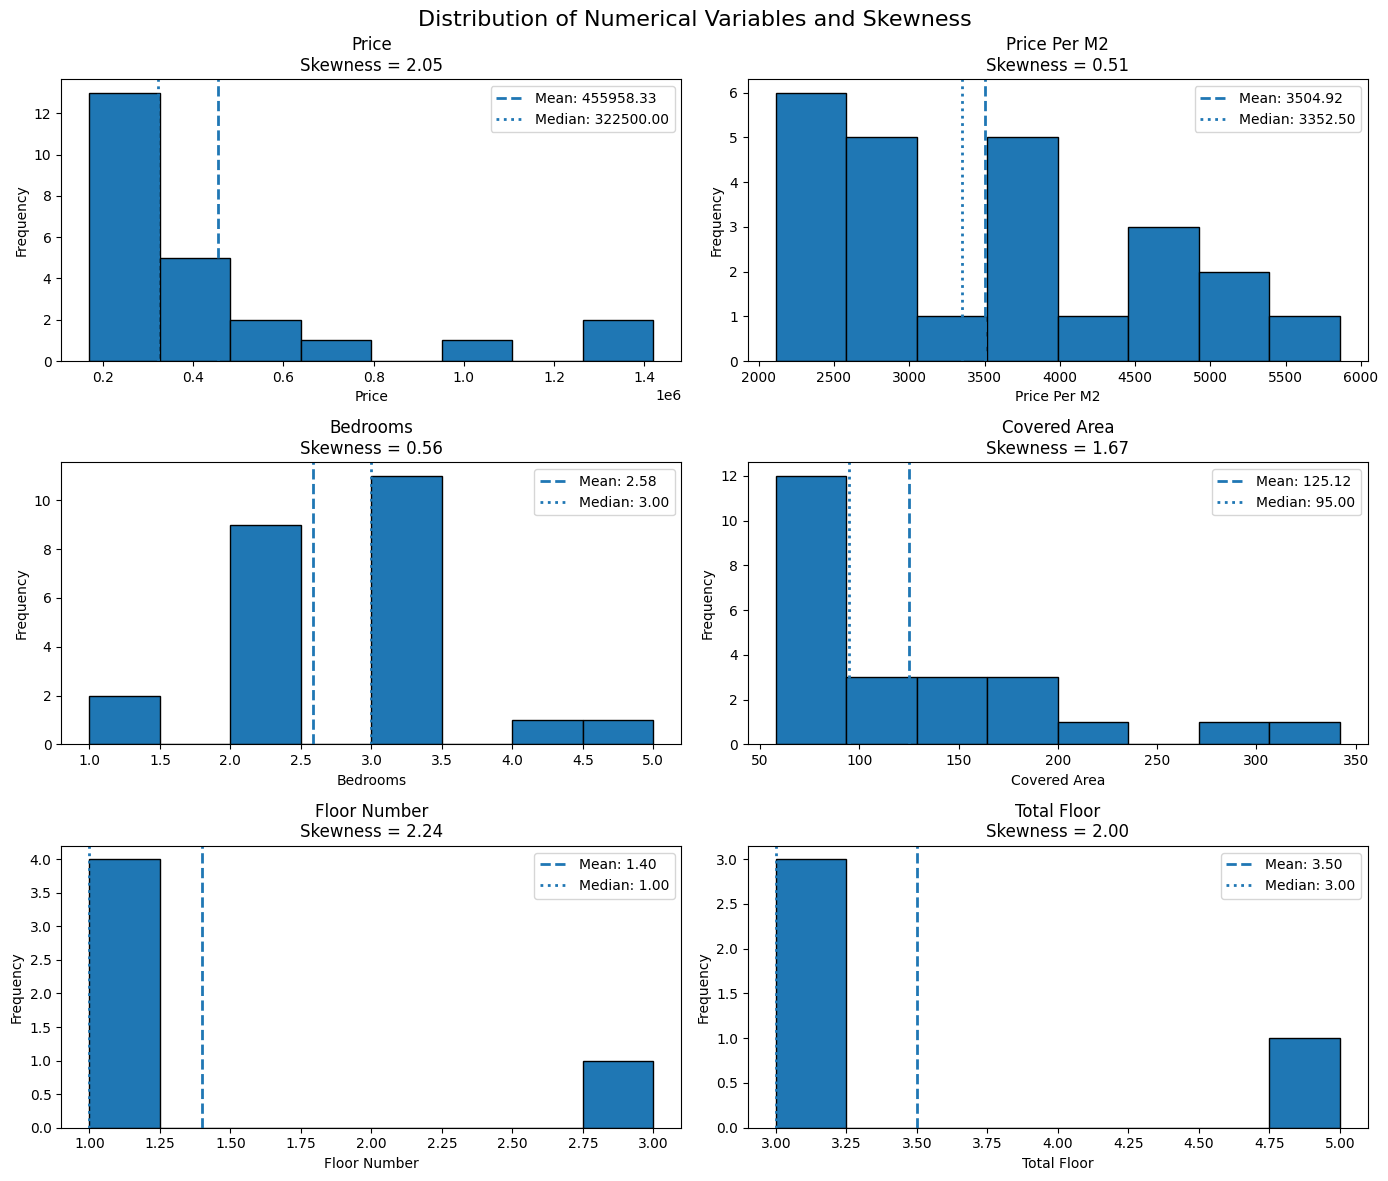

In [77]:
import matplotlib.pyplot as plt

# Calculate skewness
skewness = df_properties[numeric_cols].skew()

# Create 3 x 2 grid of histograms
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, column in zip(axes.flatten(), numeric_cols):
    
    # Histogram
    ax.hist(
        df_properties[column].dropna(),
        bins=8,
        edgecolor='black'
    )
    
    # Mean and median
    mean_value = df_properties[column].mean()
    median_value = df_properties[column].median()
    
    ax.axvline(
        mean_value,
        linestyle='--',
        linewidth=2,
        label=f'Mean: {mean_value:.2f}'
    )
    
    ax.axvline(
        median_value,
        linestyle=':',
        linewidth=2,
        label=f'Median: {median_value:.2f}'
    )
    
    # Title and labels
    ax.set_title(
        f"{column.replace('_', ' ').title()}\n"
        f"Skewness = {skewness[column]:.2f}"
    )
    
    ax.set_xlabel(column.replace('_', ' ').title())
    ax.set_ylabel("Frequency")
    
    ax.legend()

plt.suptitle(
    "Distribution of Numerical Variables and Skewness",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [78]:
#NB the most important variable here is the price variable, whereby most properties concentrated at the lower middle price
#while a few properties have very high prices
# that is why the mean is greater than the median price
# for price per_m2 which is -0.43 is ok since median is greater than mean and both are almost thesame
# this tells me the distribution is realatively balanced
# bedroom = -0.18 is relatively symmetric
#covered area at 1.67 is strongly skewed . most properties have relatively small covered area
# while a few have larger areas therefore mean is greater than median
# floor number at 1.11 is positively skewed with most floors to be lower floor while a few high floors
#total floor is the most negatively skewed 

In [79]:
# check the number of properties by district
district_counts = df_properties['district'].value_counts(dropna = False)
print(district_counts)

district
Larnaca      12
Limassol      8
Paphos        3
Famagusta     1
Name: count, dtype: int64


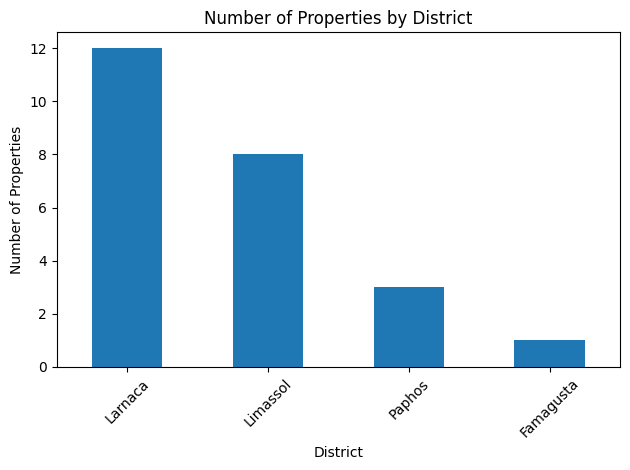

In [80]:
# visualization
plt.Figure(figsize=(10,4))
district_counts.plot(kind = 'bar')
plt.title('Number of Properties by District')
plt.xlabel('District')
plt.ylabel('Number of Properties')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [81]:
district_analysis = (df_properties.groupby('district').agg(
    number_of_properties = ('property_id','count'),
    average_price = ('price','mean'),
    median_price = ('price','median'),
    average_price_per_m2 = ('price_per_m2','mean'),
    median_price_per_m2 = ('price_per_m2','median')).round(2)

)
district_analysis

,number_of_properties,average_price,median_price,average_price_per_m2,median_price_per_m2
district,,,,,
Famagusta,1,226000.00,226000.0,3013.00,3013.0
Larnaca,12,455166.67,285000.0,3069.67,2727.5
Limassol,8,532500.00,392500.0,4202.38,4155.5
Paphos,3,331666.67,320000.0,3550.00,2910.0


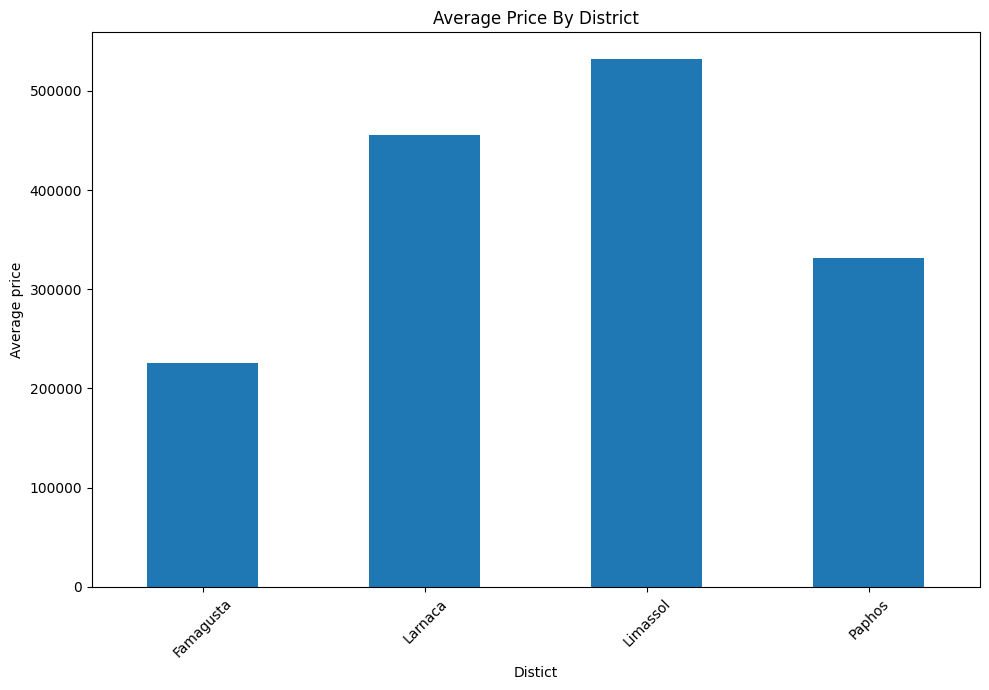

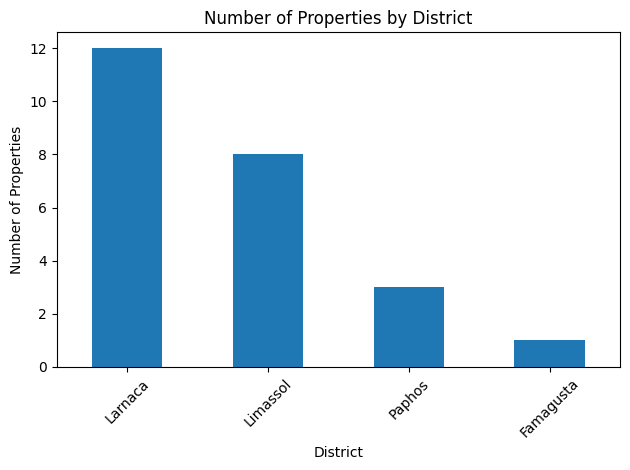

In [82]:
#average price by district
plt.figure(figsize=(10,7))
district_analysis['average_price'].plot(kind = 'bar')
plt.title('Average Price By District')
plt.xlabel('Distict')
plt.ylabel('Average price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.Figure(figsize=(10,4))
district_counts.plot(kind = 'bar')
plt.title('Number of Properties by District')
plt.xlabel('District')
plt.ylabel('Number of Properties')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [83]:
# i will focus on categorical correlations
correlation_matrix = df_properties[numeric_cols].corr()
correlation_matrix.round(2)

,price,price_per_m2,bedrooms,covered_area,floor_number,total_floor
price,1.00,0.48,0.61,0.31,0.65,0.51
price_per_m2,0.48,1.00,-0.13,0.15,-0.42,0.06
bedrooms,0.61,-0.13,1.00,0.11,0.38,-0.17
covered_area,0.31,0.15,0.11,1.00,-0.36,-0.01
floor_number,0.65,-0.42,0.38,-0.36,1.00,-0.33
total_floor,0.51,0.06,-0.17,-0.01,-0.33,1.00


<Axes: >

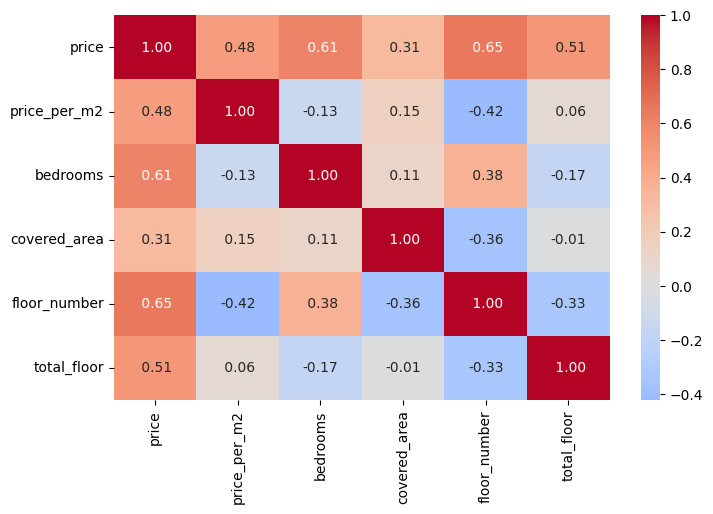

In [96]:
#visualizing the relationship
import seaborn as sns
plt.figure(figsize=(8,5))
sns.heatmap(
    correlation_matrix,annot = True,cmap = 'coolwarm',fmt =' .2f', center = 0


)

In [85]:
# floor number vs total floor -90 is extremely strong
# i will investigate
df_properties[['bedrooms','covered_area','floor','total_floor']].sort_values('total_floor')

,bedrooms,covered_area,floor,total_floor
4,3,136,1 of 3,3.0
6,1,64,1 of 3,3.0
13,3,78,3 of 3,3.0
8,2,92,1 of 5,5.0
0,4,106,None,NaN
1,3,98,None,NaN
2,2,342,None,NaN
3,2,86,None,NaN
5,3,143,None,NaN
7,1,61,None,NaN


In [86]:
df_properties[['floor','total_floor']].value_counts().sort_index()

floor   total_floor
1 of 3  3.0            2
1 of 5  5.0            1
3 of 3  3.0            1
Name: count, dtype: int64

In [ ]:
#conclusion the relationship floor and total floor are misleading as well as 
#bedrooms and total floor

In [87]:
df_properties[['floor','total_floor']].head(24)

,floor,total_floor
0,None,NaN
1,None,NaN
2,None,NaN
3,None,NaN
4,1 of 3,3.0
5,None,NaN
6,1 of 3,3.0
7,None,NaN
8,1 of 5,5.0
9,None,NaN


In [ ]:
#floor number was wrongly extracted reason for the high correlation
df_properties['floor_number'] = (
    df_properties['floor']
    .str.extract(r'(\d+)', expand=False)
    .astype(float)
)

df_properties[['floor', 'floor_number', 'total_floor']].head(24)

,floor,floor_number,total_floor
0,None,NaN,NaN
1,None,NaN,NaN
2,None,NaN,NaN
3,None,NaN,NaN
4,1 of 3,1.0,3.0
5,None,NaN,NaN
6,1 of 3,1.0,3.0
7,None,NaN,NaN
8,1 of 5,1.0,5.0
9,None,NaN,NaN


In [89]:
print("Floor number available:", df_properties['floor_number'].notna().sum())
print("Total floor available:", df_properties['total_floor'].notna().sum())
print("Total properties:", len(df_properties))

Floor number available: 5
Total floor available: 4
Total properties: 24


In [ ]:
# i will exclude floor related correlation from my conclusion ,too few information

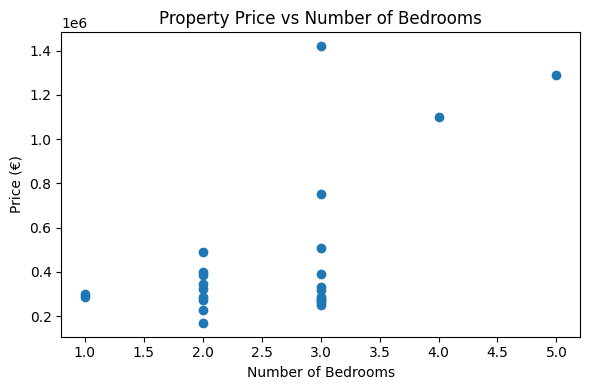

In [95]:
#bedrooms v price
plt.figure(figsize=(6, 4))

plt.scatter(
    df_properties['bedrooms'],
    df_properties['price']
)

plt.title('Property Price vs Number of Bedrooms')
plt.xlabel('Number of Bedrooms')
plt.ylabel('Price (€)')

plt.tight_layout()
plt.show()

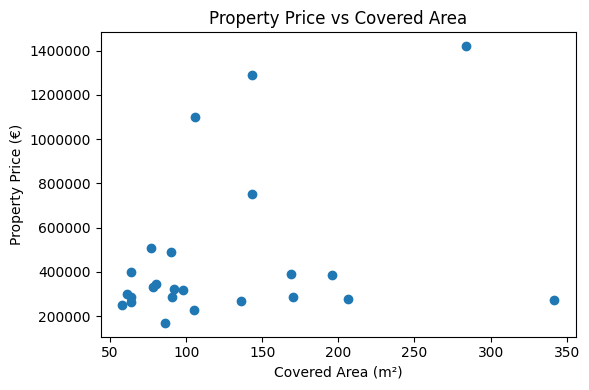

In [94]:
#covered area v price 
plt.figure(figsize=(6, 4))

plt.scatter(
    df_properties['covered_area'],
    df_properties['price']
)

plt.title('Property Price vs Covered Area')
plt.xlabel('Covered Area (m²)')
plt.ylabel('Property Price (€)')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

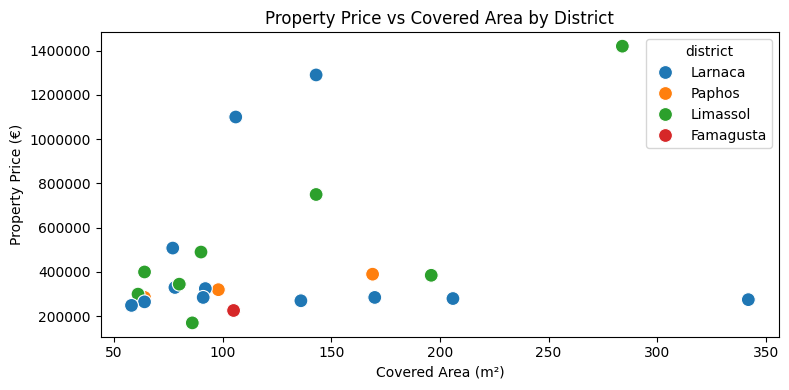

In [98]:
#conclusion larger area does not consistently correspond to higher total price 
# but a 100m2 property in limassol has a different asking price than same property in another district
# so is the weak area price caused by district differences?
plt.figure(figsize=(8, 4))

sns.scatterplot(
    data=df_properties,
    x='covered_area',
    y='price',
    hue='district',
    s=100
)

plt.title('Property Price vs Covered Area by District')
plt.xlabel('Covered Area (m²)')
plt.ylabel('Property Price (€)')

plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

In [ ]:
# conclusion property size does not play explain the asking price in this sample
# location, district and property-specific x-tics appear to play an important role

In [99]:
# before moving to looker studio to create the dashboard lets create the dataset
dashboard_df = df_properties[
    [
        'property_id',
        'title',
        'district',
        'location',
        'price',
        'price_per_m2',
        'bedrooms',
        'bathrooms',
        'covered_area',
        'parking',
        'floor_number',
        'total_floor'
    ]
].copy()

dashboard_df.head()

,property_id,title,district,location,price,price_per_m2,bedrooms,bathrooms,covered_area,parking,floor_number,total_floor
0,11739916,4 Bedroom House for Sale in Larnaca District,Larnaca,Larnaca district,1100000,2857,4,4,106,unknown,NaN,NaN
1,10659805,"3 Bedroom House for Sale in Tremithousa, Papho...",Paphos,"Tremithousa, Paphos district",320000,2909,3,2,98,unknown,NaN,NaN
2,11688774,"2 Bedroom Apartment for Sale in Oroklini, Larn...",Larnaca,"Oroklini, Larnaca district",275000,3819,2,3,342,Covered,NaN,NaN
3,11545923,"2 Bedroom Apartment for Sale in Palodeia, Lima...",Limassol,"Palodeia, Limassol district",170000,2179,2,1,86,Covered,NaN,NaN
4,10866479,3 Bedroom Apartment for Sale in Livadia Larnak...,Larnaca,"Livadia Larnakas, Larnaca district",270000,2143,3,2,136,Covered,1.0,3.0


In [100]:
# saving the final cleaned dataset
dashboard_df.to_csv("cyprus_property_cleaned.csv", index = False)
print("Data saved successfully!")



Data saved successfully!


In [101]:
import os
print(os.path.exists("cyprus_property_cleaned.csv"))

True


In [102]:
os.listdir()

['cyprus_property_cleaned.csv', 'property_scraping.ipynb']